# Meta SAM 3 & SAM 3.1 First-Principles Engine Tutorial

This notebook demonstrates the unified **`sam3_engine`** module built directly on Meta's native foundation architecture (`sam3`).

### Architectural Pillars:
1. **Local Foundation Checkpoint**: Loaded strictly from local storage (`workspace/checkpoints/pretrained/sam3vlm/`)—no arbitrary Hugging Face downloads.
2. **Unified Data Structures**: All predictions return `list[Result]` (order matches image batch index or video frame index).
3. **Open-Vocabulary Promptable Concept Segmentation (PCS)**: Text queries, visual exemplar boxes, and cached concept embeddings.
4. **Promptable Visual Segmentation (PVS)**: Interactive click and box refinement with low-resolution mask feedback.
5. **PCS <-> PVS Transition**: Detections from PCS populate object slots that can be immediately refined or deleted with PVS.
6. **In-Memory Video Tracking**: Operates natively on `list[Image.Image]`, eliminating FPS and timestamp ambiguity.

## 1. Setup & Engine Initialization

Initialize `SAM3Engine` using the unified local checkpoint (`sam3.1_multiplex.pt` or `sam3.pt`).

In [30]:
import os
import sys
from PIL import Image
import matplotlib.pyplot as plt

# try:
#     # from anywhere, given u installed in editable mode
#     from sam3_engine import SAM3Engine, Visualiser, load_video_frames
# except:
#     # from root dir
#     from src import SAM3Engine, Visualiser, load_video_frames
from sam3_engine import SAM3Engine, Visualiser, load_video_frames
    

# Initialize unified engine (loads local foundation checkpoint)
engine = SAM3Engine(
    device="cuda",
    video_checkpoint_path="/home/nic/projects/rin/workspace/checkpoints/pretrained/sam3vlm/sam3.pt",
    image_checkpoint_path="/home/nic/projects/rin/workspace/checkpoints/pretrained/sam3vlm/sam3.pt",
    bpe_path="/home/nic/projects/rin/workspace/checkpoints/pretrained/sam3vlm/bpe_simple_vocab_16e6.txt.gz",
    video_version='sam3',
    precision="bfloat16",
    confidence_threshold=0.4,
)

print("SAM 3 Engine successfully initialized!")

SAM 3 Engine successfully initialized!


**Dynamic Confidence Threshold**

The threshold can be adjusted dynamically at any time across both image and video sub-engines.

In [31]:
# Adjust threshold dynamically
engine.set_threshold(0.35)
print(f"Active confidence threshold: {engine.confidence_threshold}")

Active confidence threshold: 0.35


## 2. Image Concept Grounding (PCS) with Concept Caching

1. Pass one or more PIL images via `engine.image.initialise(images: list[Image.Image])`. Vision backbone features are precomputed and cached in GPU memory.
2. Precompute open-vocabulary concept text embeddings once via `engine.encode_concept("concept")` (image and video invariant).
3. Add concepts to active configuration:
   - `engine.image.add_concept(concept, name="...")` for text concepts (supports string or precomputed `CachedConcept`).
   - `engine.image.add_exemplar([x1, y1, x2, y2], label=1)` for geometric exemplar boxes.
4. Predict concept masks across all initialized images via `engine.image.predict_pcs()`, returning `list[Result]` via `engine.image.get_results`.

Detected 6 objects on wildlife image.
  [ID 1] giraffe (0.93) -> (726.1498413085938, 234.65882873535156, 1052.958984375, 482.98602294921875)
  [ID 2] giraffe (0.96) -> (251.12094116210938, 166.75311279296875, 734.2472534179688, 475.9256591796875)
  [ID 3] zebra (0.96) -> (964.2320556640625, 397.71087646484375, 1288.0819091796875, 651.9880981445312)
  [ID 4] zebra (0.97) -> (38.545654296875, 400.3151550292969, 427.8365478515625, 637.4292602539062)
  [ID 5] zebra (0.96) -> (737.86376953125, 447.7369079589844, 1008.0695190429688, 642.006103515625)
  [ID 6] zebra (0.96) -> (419.4987487792969, 436.9518737792969, 771.333251953125, 640.2977294921875)


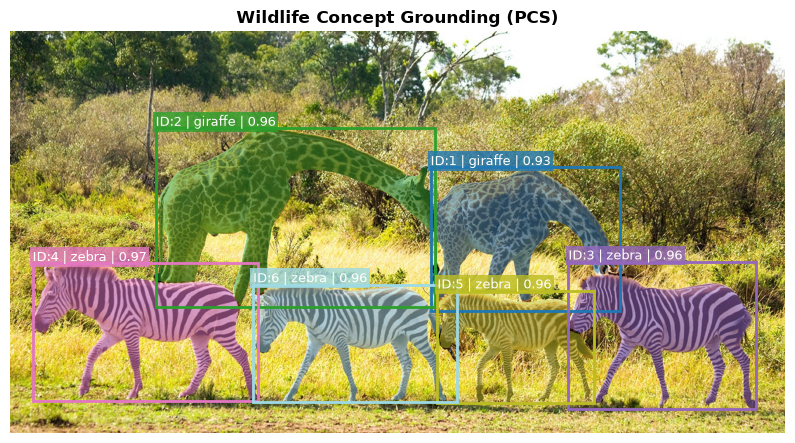

In [50]:
wildlife_path = "./assets/images/wildlife.jpg"
wildlife = Image.open(wildlife_path).convert("RGB")

# 1. Initialize image session (extracts vision backbone features once)
engine.image.initialise([wildlife])

# 2. Precompute concept text embeddings (image & video invariant)
text_giraffe = engine.encode_concept("giraffe")
text_zebra = engine.encode_concept("zebra")

# 3. Add concepts to active PCS configuration
engine.image.add_concept(text_giraffe)
engine.image.add_concept(text_zebra)

# 4. Predict PCS across all initialized images
engine.image.predict_pcs()
results = engine.image.get_results()

print(f"Detected {len(results[0]['masks'])} objects on wildlife image.")
for obj_id, label, score, box in zip(
    results[0]["object_ids"],
    results[0]["labels"],
    results[0]["scores"],
    results[0]["boxes"],
):
    print(f"  [ID {obj_id}] {label} ({score:.2f}) -> {box}")

# 5. Visualise results
Visualiser.visualise(results[0], wildlife, title="Wildlife Concept Grounding (PCS)")
plt.show()

**Visual Exemplar Box Grounding**

Condition the detector on spatial exemplar box prompt(s) `[x1, y1, x2, y2]` to ground all matching instances via `engine.image.add_exemplar(box, label=1)`.

*Note: can't be used with image concepts above hybridly*

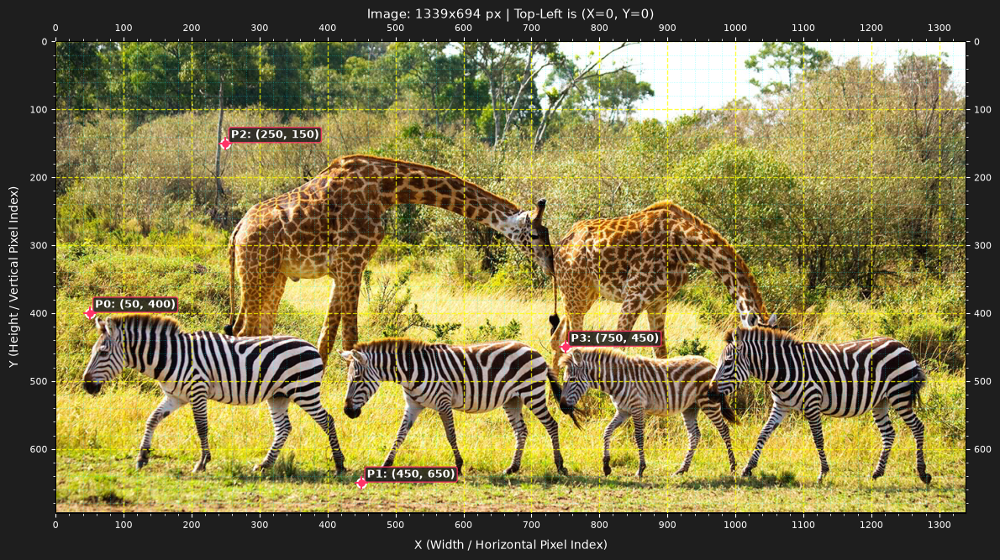

In [51]:
Visualiser.show_image_with_grid(wildlife, points=[(50, 400), (450, 650), (250, 150), (750, 450)])

Here we try to remove giraffes via exemplars

Detected 4 objects via exemplar grounding.


<Axes: title={'center': 'Visual Exemplar Grounding'}>

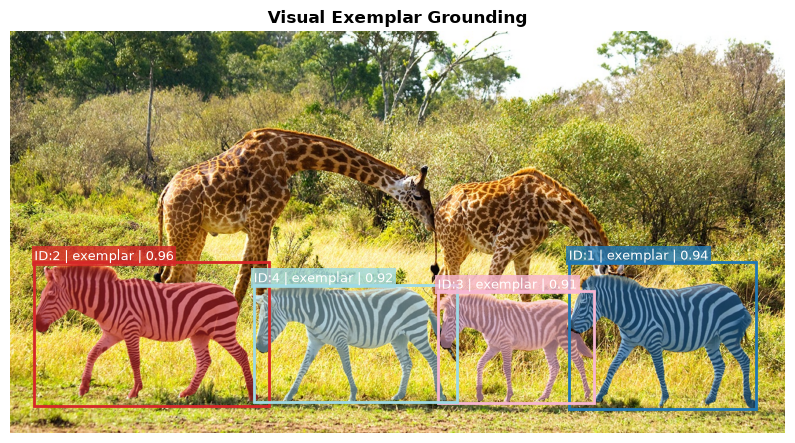

In [52]:
# Clear previous text concepts to evaluate pure exemplar grounding
engine.image.reset_state()

# Add negative visual exemplar box on giraffe specifically
engine.image.add_exemplar(box=(50, 400, 450, 650), label=1)
engine.image.add_exemplar(box=(250, 150, 750, 450), label=0)

# Predict with active exemplar concepts
engine.image.predict_pcs()
results_ex = engine.image.get_results()

print(f"Detected {len(results_ex[0]['masks'])} objects via exemplar grounding.")
Visualiser.visualise(results_ex[0], wildlife, title="Visual Exemplar Grounding")


## 3. Interactive Instance Segmentation (PVS)

Use interactive click and box prompts on individual object slots:
- `set_object(int)`: selects or creates an object slot.
- `add_points(points, label)`: adds positive (`1`) or negative (`0`) prompt clicks.
- `add_box(box)`: adds bounding box prompt.
- `predict_pvs()`: predicts and refines the mask using low-resolution mask feedback.
- `get_results()`: returns the current state of prediction

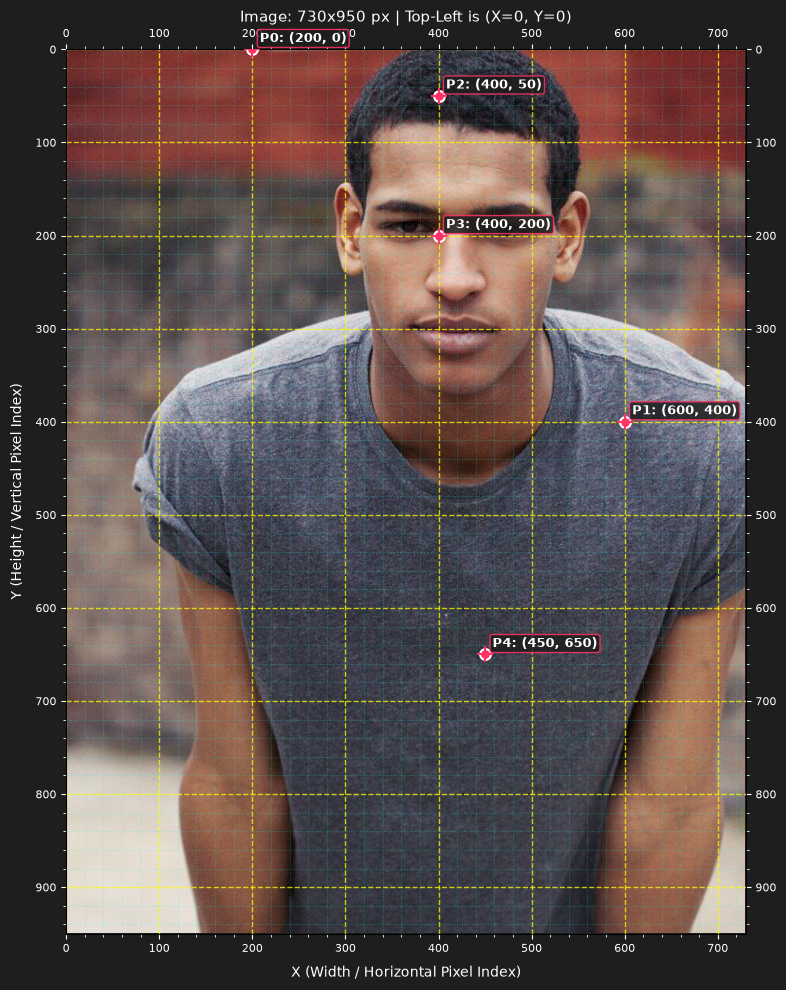

In [6]:
human_path = "./assets/images/human.jpg"
human = Image.open(human_path).convert("RGB")
Visualiser.show_image_with_grid(human, points=[(200, 0), (600, 400), (400, 50), (400, 200), (450, 650)])

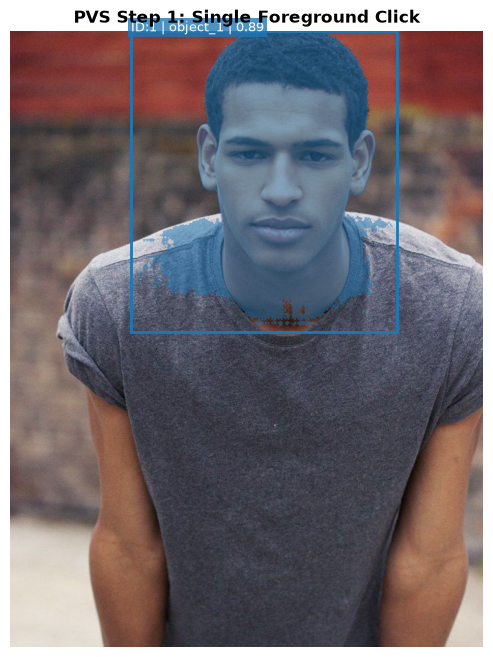

In [7]:
# Initialize session on aquatic image
engine.image.initialise([human])

# Step 1: Select object slot 1 and add positive click on target yellow fish
engine.image.set_object(1)
engine.image.add_box(box=(200, 0, 600, 400))
engine.image.add_points(points=[(400, 200)], label=[1])
engine.image.predict_pvs()
results_pvs1 = engine.image.get_results()

Visualiser.visualise(results_pvs1[0], human, title="PVS Step 1: Single Foreground Click")
plt.show()


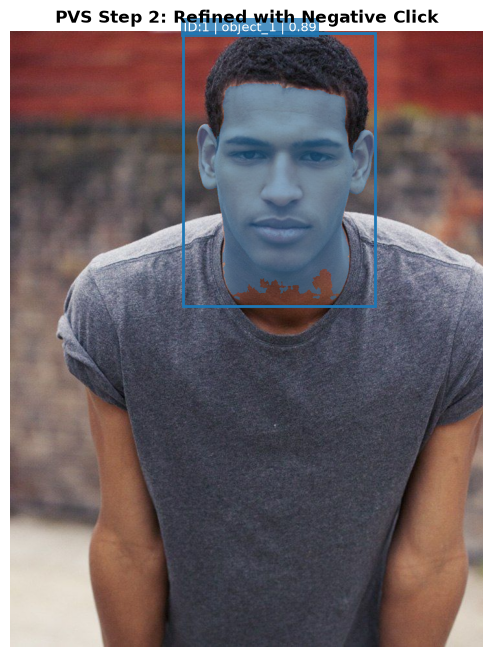

In [8]:
# Step 2: Refine object 1 with a negative click (label=0) on the background boundary
engine.image.set_object(1)
engine.image.add_points(points=[(400, 50)], label=[0])
engine.image.predict_pvs()
results_pvs2 = engine.image.get_results()

Visualiser.visualise(results_pvs2[0], human, title="PVS Step 2: Refined with Negative Click")
plt.show()

## 4. Seamless PCS <-> PVS Transition

Objects detected by PCS automatically populate internal object slots (IDs 1, 2, 3...).
You can seamlessly select any PCS-detected object via `set_object(id)` to refine it with clicks/boxes, or delete unwanted objects via `del_object(id)`.

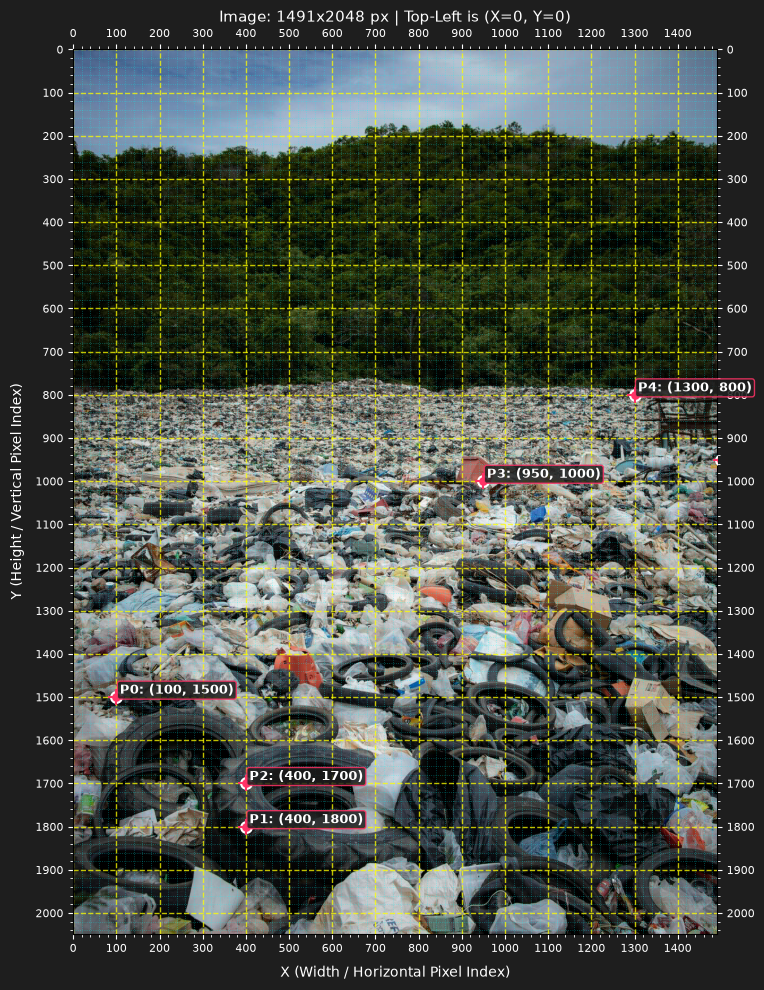

In [9]:
trash_path = "./assets/images/trash.jpg"
trash = Image.open(trash_path).convert("RGB")
Visualiser.show_image_with_grid(trash, points=[(100, 1500), (400, 1800), (400, 1700), (950, 1000), (1300, 800), (1500, 950)])

Here we do a 'stuff' segmentation via `trash pile`

Initial PCS Object IDs: [1]


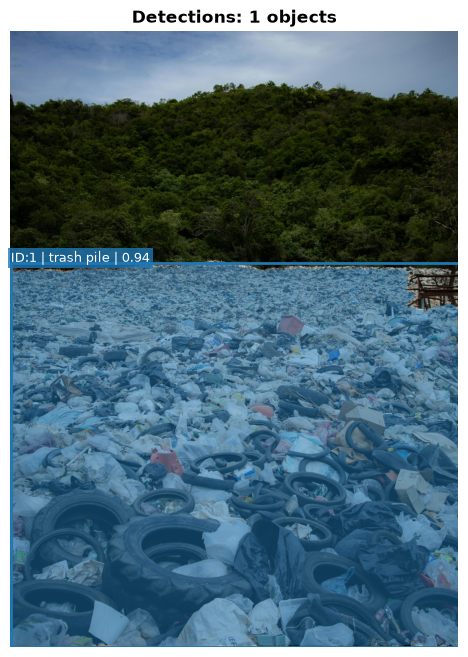

In [10]:
# Initialize trash image and run PCS
engine.image.initialise([trash])
trash_concept = engine.encode_concept("trash pile")
engine.image.add_concept(trash_concept)

engine.image.predict_pcs(trash_concept)
results_trans = engine.image.get_results()

print("Initial PCS Object IDs:", results_trans[0]["object_ids"])
Visualiser.visualise(
    result=results_trans[0],
    image=trash,
)
plt.show()

Refine Object 1 using a click prompt

here we select via box or points to guide 'trash pile' to a specific tire (demo only, bad example btw)

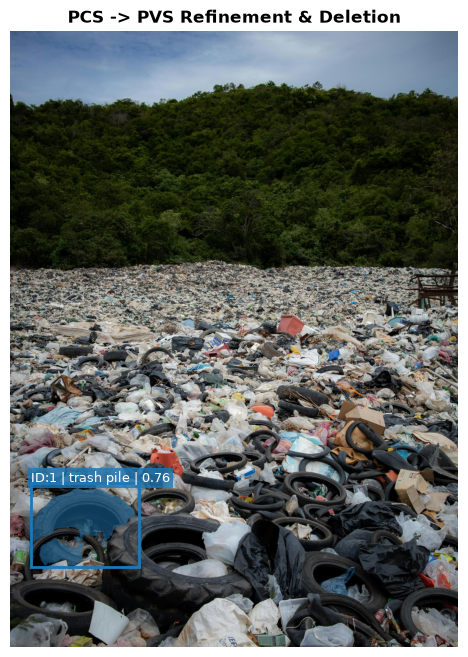

In [11]:
engine.image.set_image_idx(0)
engine.image.set_object(1)

# engine.image.add_points(points=[(400, 1700)], label=[1])  # or refine with points up to u
engine.image.add_box(box=(100, 1500, 400, 1800))
engine.image.predict_pvs()
results_refined = engine.image.get_results()
Visualiser.visualise(results_refined[0], trash, title="PCS -> PVS Refinement & Deletion")
plt.show()

Add objects (PVS)

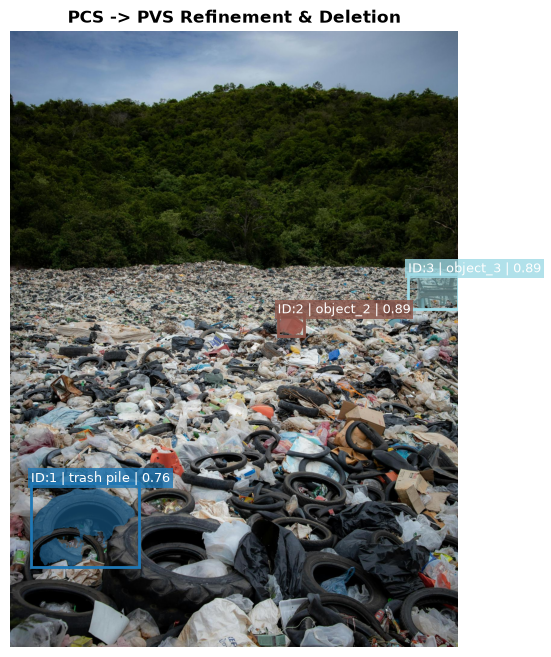

In [12]:
engine.image.set_image_idx(0)

engine.image.set_object(2)
engine.image.add_points(points=[(950, 1000)], label=[1])

engine.image.set_object(3)
engine.image.add_box(box=(1300, 800, 1500, 950))
engine.image.predict_pvs()

final_results = engine.image.get_results()

Visualiser.visualise(final_results[0], trash, title="PCS -> PVS Refinement & Deletion")
plt.show()

Delete objects

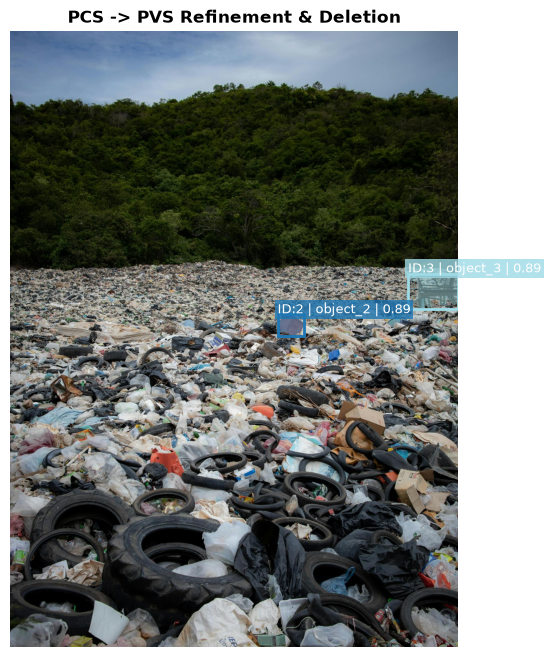

In [13]:
engine.image.del_object(1)
final_res = engine.image.get_results()
Visualiser.visualise(final_res[0], trash, title="PCS -> PVS Refinement & Deletion")
plt.show()

## 5. Batch Inference

You can run multiple images at once efficiently here (with encode concept)

You can also choose a specific image idx to continue: run pvs (refinement/new objects)

In [14]:
tea1_path = "./assets/images/tea1.jpg"
tea2_path = "./assets/images/tea2.jpg"

tea1 = Image.open(tea1_path).convert("RGB")
tea2 = Image.open(tea2_path).convert("RGB")

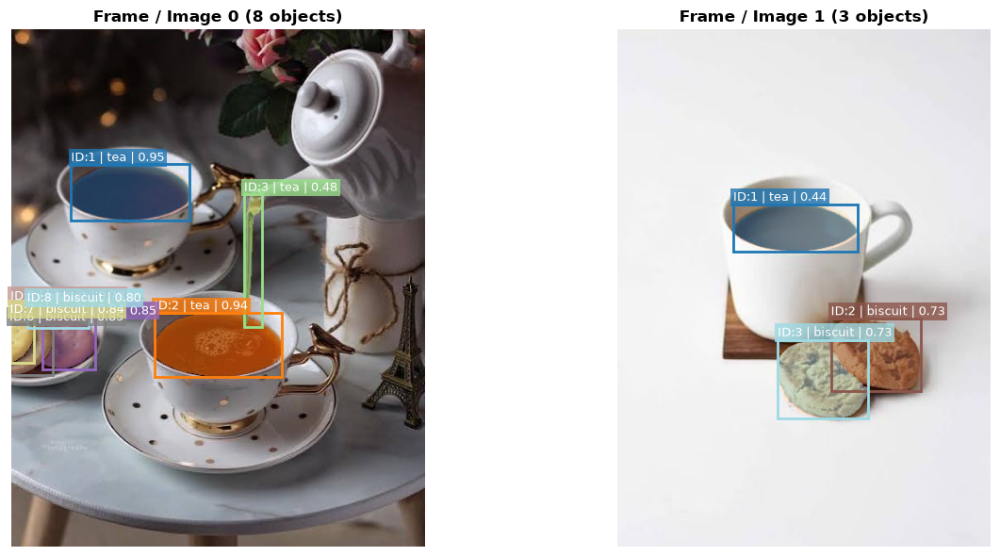

In [15]:
engine.image.initialise([tea1, tea2])

tea_concept = engine.encode_concept('tea')
biscuit_concept = engine.encode_concept('biscuit')

engine.image.reset_state()
engine.image.add_concept(tea_concept)
engine.image.add_concept(biscuit_concept)

engine.image.predict_pcs()
results = engine.image.get_results()
Visualiser.visualise_batch(
    results=results,
    images=[tea1, tea2],
)
plt.show()

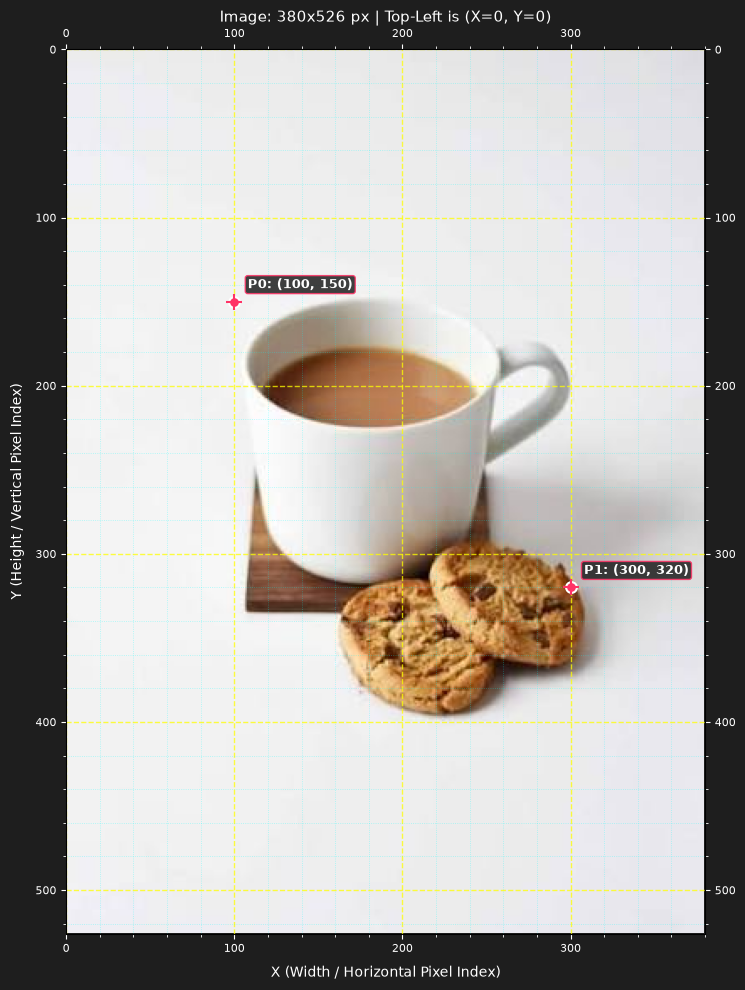

In [16]:
Visualiser.show_image_with_grid(tea2, points=[(100, 150), (300, 320)])

Here we demo by adding a box to tea for the whole cup (cup != tea) so we get a bit pixelated mask

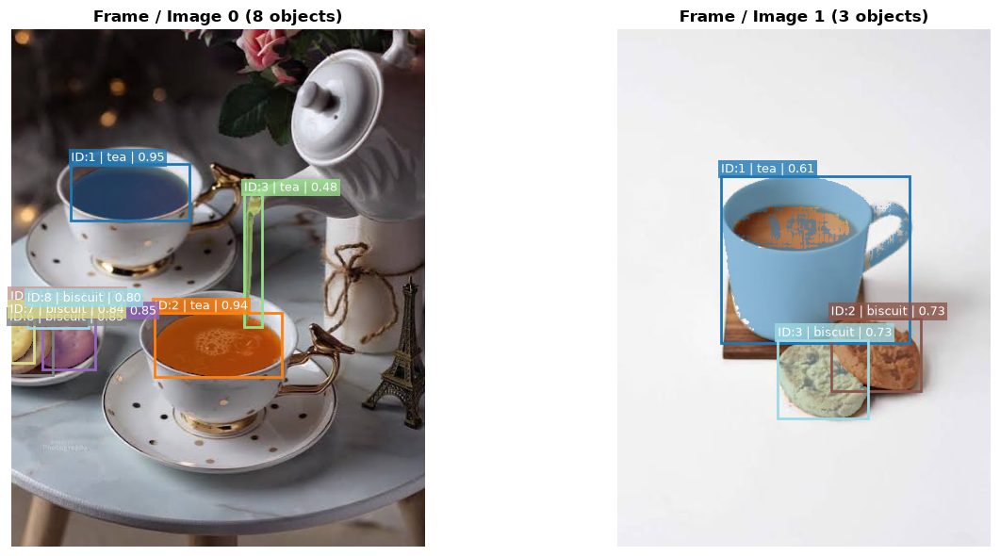

In [17]:
engine.image.set_image_idx(1)
engine.image.set_object(1)
engine.image.add_box(box=(100, 150, 300, 320))
engine.image.predict_pvs()
results_pvs = engine.image.get_results()

Visualiser.visualise_batch(
    results=results_pvs,
    images=[tea1, tea2],
)
plt.show()

## 6. In-Memory Video Tracking with SAM 3.1 Object Multiplex

1. Extract video frames as a list of raw PIL images (`list[Image.Image]`), avoiding FPS or timestamp ambiguity.
2. Pass `frames` to `engine.video.initialise(frames)`.
3. Support both Keyframe **PCS** (`add_concept`, `add_exemplar`, `predict_pcs()`) and **PVS** (`set_object`, `add_points`, `add_box`, `predict_pvs()`).
4. Run `engine.video.propagate() -> list[Result]` to track all objects bidirectionally across the full video sequence.

In [18]:
video_path = "./assets/videos/01_dog.mp4"

# Load video frames into list[Image.Image]
frames = load_video_frames(video_path, max_frames=24, stride=2)
print(f"Loaded {len(frames)} frames from video.")

# Initialize video session
engine.video.initialise(frames)
tgt_idx = 3

INFO 2026-10-10 23:39:07,434 2725754 sam3_video_predictor.py: 120: using the following GPU IDs: [0]
INFO 2026-10-10 23:39:07,436 2725754 sam3_video_predictor.py: 136: 


	*** START loading model on all ranks ***


INFO 2026-10-10 23:39:07,436 2725754 sam3_video_predictor.py: 138: loading model on rank=0 with world_size=1 -- this could take a while ...


Loaded 24 frames from video.


INFO 2026-10-10 23:39:12,075 2725754 sam3_video_base.py: 354: setting max_num_objects=10000 and num_obj_for_compile=16
INFO 2026-10-10 23:39:14,985 2725754 sam3_video_predictor.py: 140: loading model on rank=0 with world_size=1 -- DONE locally
INFO 2026-10-10 23:39:14,986 2725754 sam3_video_predictor.py: 151: 


	*** DONE loading model on all ranks ***


INFO 2026-10-10 23:39:15,486 2725754 sam3_base_predictor.py: 167: started new session 17dde0e7-f0f8-45ee-9565-ee1d7297e3f0


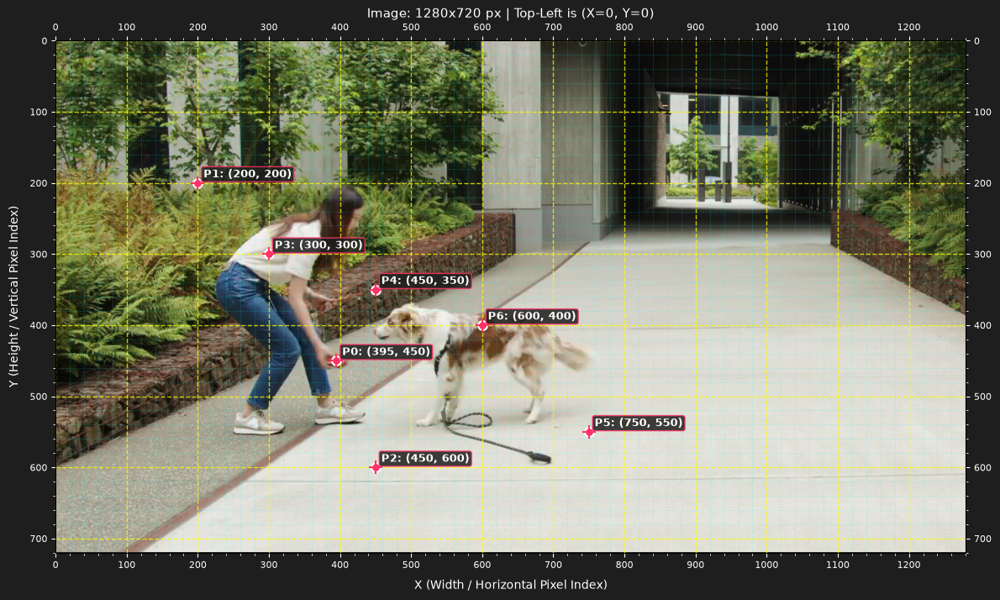

In [19]:
Visualiser.show_image_with_grid(frames[tgt_idx], points=[(395, 450), (200, 200), (450, 600), (300, 300), (450, 350), (750, 550), (600, 400)])

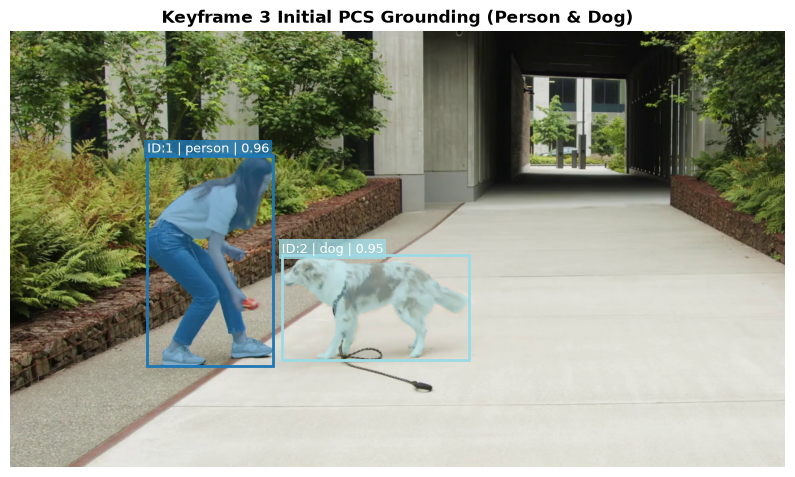

In [20]:
# 1. Keyframe PCS (Promptable Concept Segmentation)
engine.video.set_frame_idx(tgt_idx)

person_concept = engine.encode_concept('person')
dog_concept = engine.encode_concept('dog')

engine.video.reset_state()
engine.video.add_concept(person_concept)
engine.video.add_concept(dog_concept)
frame_results_pcs = engine.video.predict_pcs()
frame_results_pcs = engine.video.get_results()

Visualiser.visualise(
    result=frame_results_pcs[tgt_idx],
    image=frames[tgt_idx],
    title=f"Keyframe {tgt_idx} Initial PCS Grounding (Person & Dog)",
)
plt.show()

Can add the ball to the object 1 (ball and person joined)

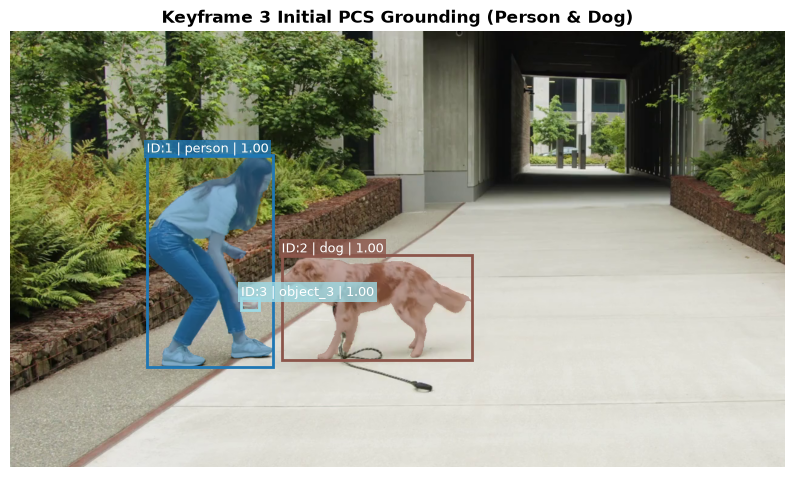

In [21]:
# Step 1: Object 1 (Dog) - positive foreground click at (600, 400)
engine.video.set_object(3)
engine.video.add_points(points=(400, 450), label=1)
engine.video.predict_pvs()
frame_results_pvs = engine.video.get_results()

Visualiser.visualise(
    result=frame_results_pvs[tgt_idx],
    image=frames[tgt_idx],
    title=f"Keyframe {tgt_idx} Initial PCS Grounding (Person & Dog)",
)
plt.show()

**Propagate Tracking Across All Frames**

Once keyframes are prompted with PCS or PVS, run bidirectional tracking across all frames in memory. The return value is strictly `list[Result]` matching the video frame count 1-to-1.

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

INFO 2026-10-10 23:39:24,286 2725754 sam3_base_predictor.py: 363: propagation ended in session 17dde0e7-f0f8-45ee-9565-ee1d7297e3f0


Successfully propagated tracking across 24 frames!


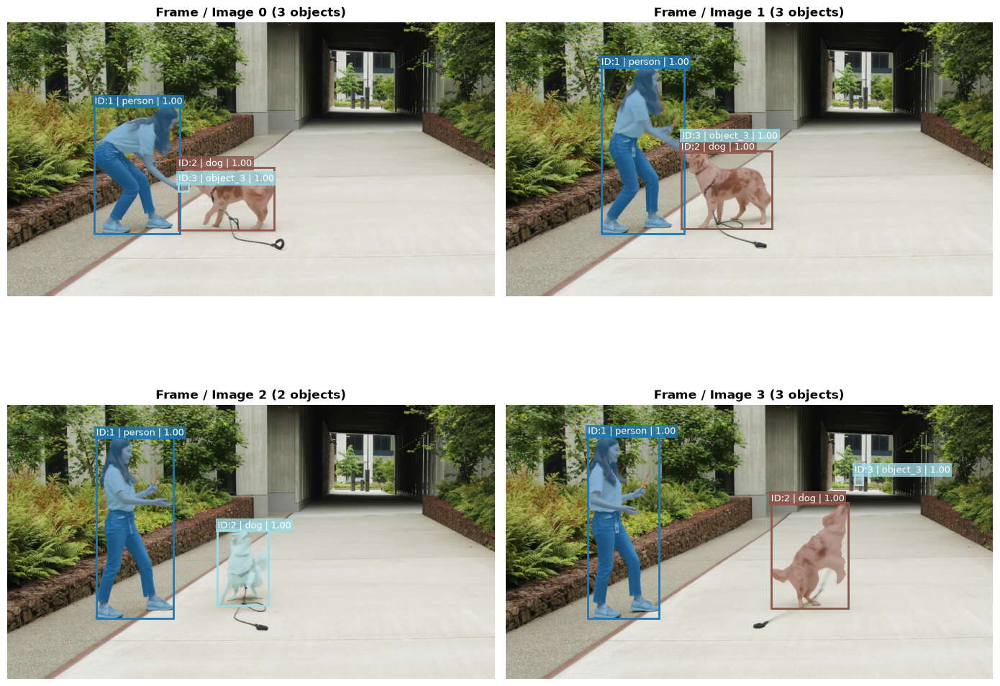

In [22]:
# Propagate throughout the video
video_results = engine.video.propagate()
print(f"Successfully propagated tracking across {len(video_results)} frames!")

# Sample and visualise key frames
sample_indices = [0, len(frames) // 3, 2 * len(frames) // 3, len(frames) - 1]
fig = Visualiser.visualise_batch(
    results=[video_results[i] for i in sample_indices],
    images=[frames[i] for i in sample_indices],
    cols=2,
)
plt.show()

Keyframe PVS (Promptable Visual Segmentation with Points & Box)

You can also track manually (sam2 application)

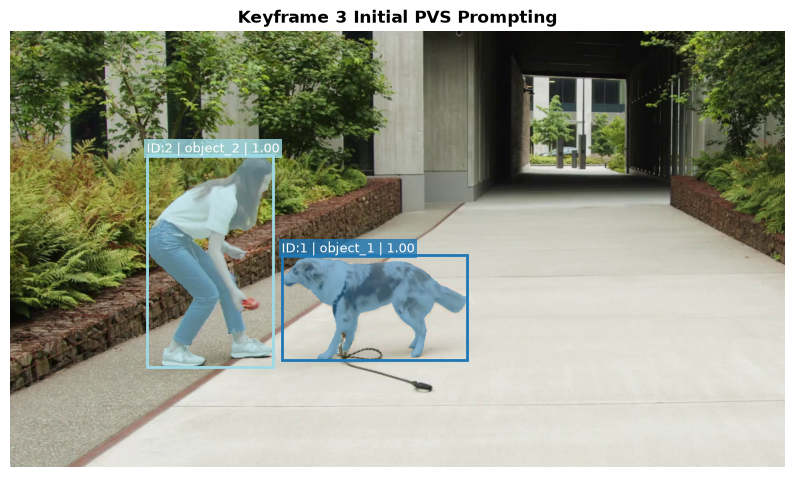

In [23]:
engine.video.reset_state()

# Step 1: Object 1 (Dog) - positive foreground click at (600, 400)
engine.video.set_object(1)
engine.video.add_points(points=(600, 400), label=1)
engine.video.predict_pvs()

# Step 2: Object 2 (Person) - bounding box prompt at (200, 200, 450, 600)
engine.video.set_object(2)
engine.video.add_box(box=(200, 200, 450, 600))
engine.video.predict_pvs()

frame_results_pvs = engine.video.get_results()

Visualiser.visualise(
    result=frame_results_pvs[tgt_idx],
    image=frames[tgt_idx],
    title=f"Keyframe {tgt_idx} Initial PVS Prompting",
)
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

INFO 2026-10-10 23:39:30,500 2725754 sam3_base_predictor.py: 363: propagation ended in session 17dde0e7-f0f8-45ee-9565-ee1d7297e3f0


Successfully propagated tracking across 24 frames!


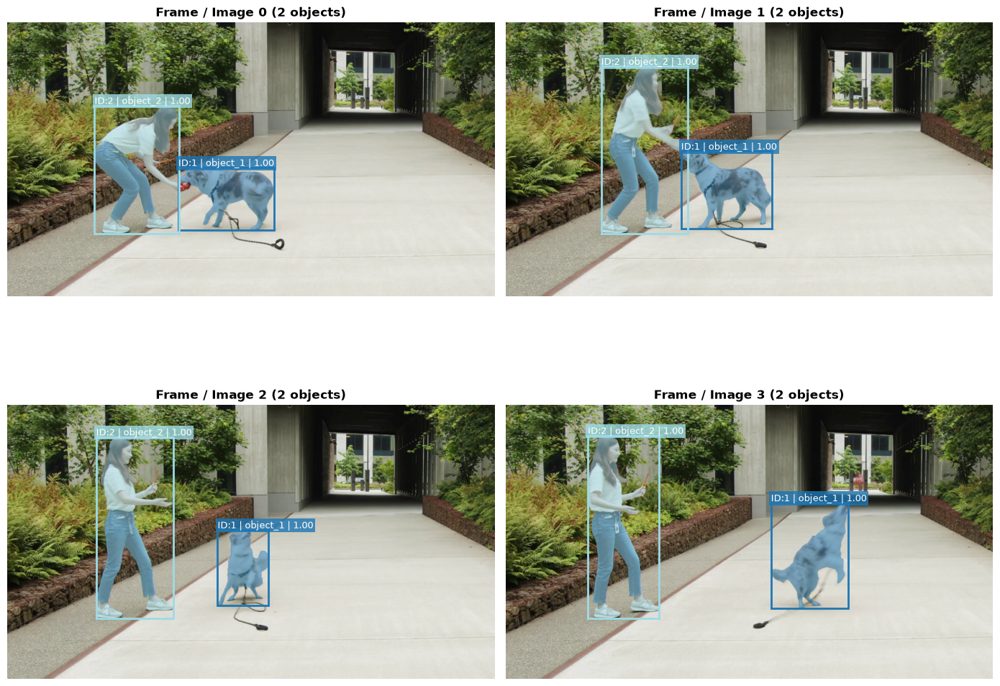

In [24]:
# Propagate throughout the video
video_results = engine.video.propagate()
print(f"Successfully propagated tracking across {len(video_results)} frames!")

# Sample and visualise key frames
sample_indices = [0, len(frames) // 3, 2 * len(frames) // 3, len(frames) - 1]
fig = Visualiser.visualise_batch(
    results=[video_results[i] for i in sample_indices],
    images=[frames[i] for i in sample_indices],
    cols=2,
)
plt.show()

## 7. Session Cleanup
Free GPU memory and clean up active sessions.

In [25]:
engine.shutdown()
print("Engine shut down and GPU memory freed.")

INFO 2026-10-10 23:39:31,567 2725754 sam3_base_predictor.py: 467: removed session 17dde0e7-f0f8-45ee-9565-ee1d7297e3f0


Engine shut down and GPU memory freed.
